# Assignment 3. Deep Learning. Liliia Yaroshenko.


In [ ]:
from google.colab import files
import pandas as pd
import glob
import ast
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
files.upload()  # pick the kaggle.json you downloaded

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"liliiayaroshenko","key":"5aea255f5726ce3c10d26075fb258189"}'}

In [3]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

In [4]:
!kaggle competitions download -c kse-ua-location-extraction-2026 -p data
!unzip -o -q data/*.zip -d data
!ls -lh data

100% 811M/811M [00:43<00:00, 19.4MB/s]

total 3.1G
-rw-r--r-- 1 root root 811M Oct 29 23:46 kse-ua-location-extraction-2026.zip
-rw-r--r-- 1 root root  15K Oct 29 15:02 labeling_sample.csv
-rw-r--r-- 1 root root 1.2K Oct 29 15:02 README.md
-rw-r--r-- 1 root root 1.9G Oct 29 16:26 ru_geo_dataset.csv
-rw-r--r-- 1 root root 338K Oct 29 21:53 test.csv
-rw-r--r-- 1 root root 202M Oct 29 21:53 uk_geo_dataset.csv
-rw-r--r-- 1 root root 181M Oct 29 22:33 uk_geo_dataset_processed_v1.parquet


In [5]:
import pandas as pd
import glob

pd.set_option("display.max_colwidth", 200)

for path in sorted(glob.glob("data/**/*.csv", recursive=True)):
    df = pd.read_csv(path)
    print("=" * 80)
    print(path)
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print(df.dtypes)
    display(df.head())

data/labeling_sample.csv
shape: (26, 3)
columns: ['text', 'locations', 'loc_markers']
text           object
locations      object
loc_markers    object
dtype: object


,text,locations,loc_markers
0,-261.310,[],[]
1,"Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь",['Проспект Бандери'],"[(0, 16)]"
2,☢️Радіаційний фон (мкР/год) по Київщині станом на 9 год 28 серпня:\n\nЧорнобиль - 19\nКиїв - 12\nТетерів - 9\nФастів - 11\nБіла Церква - 13\nМиронівка - 13\nБориспіль - 13\nЯготин - 12\nБаришівка ...,"['Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка']","[(31, 39), (68, 77), (83, 87), (93, 100), (105, 111), (117, 128), (134, 143), (149, 158), (164, 170), (176, 185)]"
3,"Друзі. Останні дві ночі, і ще декілька наступних, ми з вами будемо відчувати певний дискомфорт у звʼязку з фінішним асфальтуванням на проспекті Івасюка. Так, нам також не дуже приємно від шуму. Ал...",['проспекті Івасюка'],"[(134, 151)]"
4,Сьогодні з Києва до Хелма вперше вирушив новий міжнародний поїзд Укрзалізниці🚊\n\nЯк він курсуватиме👈,"['Києва', 'Хелма']","[(11, 16), (20, 25)]"


data/ru_geo_dataset.csv
shape: (8028840, 6)
columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'doc_id', 'sent_id']
text           object
loc_markers    object
org_markers    object
per_markers    object
doc_id          int64
sent_id         int64
dtype: object


,text,loc_markers,org_markers,per_markers,doc_id,sent_id
0,"Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высокая смертность от рака, сообщает РИА Новости.","[(82, 88)]","[(149, 160)]","[(36, 52)]",0,0
1,"По словам Голиковой, чаще всего онкологические заболевания становились причиной смерти в Псковской, Тверской, Тульской и Орловской областях, а также в Севастополе.","[(89, 98), (100, 108), (110, 118), (121, 139), (151, 162)]",[],"[(10, 19)]",0,1
2,"Вице-премьер напомнила, что главные факторы смертности в России — рак и болезни системы кровообращения.","[(57, 63)]",[],[],0,2
3,"В начале года стало известно, что смертность от онкологических заболеваний среди россиян снизилась впервые за три года.",[],[],[],0,3
4,"По данным Росстата, в 2017 году от рака умерли 289 тысяч человек.",[],"[(10, 18)]",[],0,4


data/test.csv
shape: (477, 3)
columns: ['text_id', 'text', 'locations']
text_id       int64
text         object
locations    object
dtype: object


,text_id,text,locations
0,0,"❗️Кількість поранених зросла до трьох, – Кличко\n\nКиїв — пряма трансляція 👈",[]
1,1,"🥤В Києві за 91,13 млн гривень починаються роботи зі знесення будівлі цеху №5 заводу “Більшовик”, які необхідні для продовження реконструкції “Шулявського шляхопроводу”.\n\n🤝Договір на проведення ц...",[]
2,2,"▪️Сьогодні вночі росіяни завдали ракетного удару по селищу Гоголеве, Миргородського району Полтавської області - Офіс Президента. \n\n▪️Загинуло двоє людей\n\n💬""Унаслідок вибуху виникло загоряння ...",[]
3,3,"Наразі у запасах росіян найбільше балістичних ""Іскандерів"" й крилатих ""Калібрів"".❗️\n\nУ ГУР розповіли, скільки загалом ракет залишилось в країни-окупанта.",[]
4,4,"⛸В один день, 29 серпня, ДП ""Центральна учбово-тренувальна база по ковзанярському спорту ""Льодовий стадіон"" оголосило та одразу ж відмінило тендер вартістю 307 млн гривень на добудову Національног...",[]


data/uk_geo_dataset.csv
shape: (1010000, 5)
columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'is_valid']
text           object
loc_markers    object
org_markers    object
per_markers    object
is_valid        int64
dtype: object


,text,loc_markers,org_markers,per_markers,is_valid
0,"Чим довше мають скачки тиску гіпертензією, тим сильніше змінюються стінки цих судин.",[],[],[],0
1,"А поки що починали цвісти троянди, випускники складали іспити, учні відпочивали в пришкільному таборі, а директор Володимир Хоботов марно оббивав пороги в пошуках транспорту.",[],[],"[(114, 131)]",0
2,"Крім того, в 2020 р. багато експертів прогнозують виникнення кризових явищ на світових фінансових ринках, що може ускладнити залучення зовнішніх позик.",[],[],[],0
3,"Сильно сумніваюся, що ви зупините свій вибір на такому цілителі.",[],[],[],0
4,Цей унікальний правовий важіль утворено 1998 року в Данії.,[],[],[],0


In [6]:
for path in sorted(glob.glob("data/**/*.csv", recursive=True)):
    df = pd.read_csv(path)
    print("=" * 80)
    print(path)
    for col in df.columns:
        print(f"{col}: {repr(df[col].iloc[0])}")

data/labeling_sample.csv
text: '-261.310'
locations: '[]'
loc_markers: '[]'
data/ru_geo_dataset.csv
text: 'Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высокая смертность от рака, сообщает РИА Новости.'
loc_markers: '[(82, 88)]'
org_markers: '[(149, 160)]'
per_markers: '[(36, 52)]'
doc_id: np.int64(0)
sent_id: np.int64(0)
data/test.csv
text_id: np.int64(0)
text: '❗️Кількість поранених зросла до трьох, – Кличко\n\nКиїв — пряма трансляція 👈'
locations: '[]'
data/uk_geo_dataset.csv
text: 'Чим довше мають скачки тиску гіпертензією, тим сильніше змінюються стінки цих судин.'
loc_markers: '[]'
org_markers: '[]'
per_markers: '[]'
is_valid: np.int64(0)


## 1. EDA + metric analysis


uk           n=1,010,000  median len=  91  max len=  255  has newline=0.0%  0 locs=76.9%  mean locs=0.34
ru (sample)  n=  300,000  median len= 100  max len=  762  has newline=0.0%  0 locs=72.0%  mean locs=0.43
labeling     n=       26  median len= 218  max len= 1118  has newline=80.8%  0 locs=38.5%  mean locs=1.23
test         n=      477  median len= 264  max len= 3682  has newline=85.1%

labeling_sample locations: ['Проспект Бандери', 'Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка', 'проспекті Івасюка', 'Києва', 'Хелма', 'Києву', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', 'Троєщині', 'Шевченківському районі', 'Героїв Дніпра', "вул. Солом'янська, 28", 'Києвом', 'Васильковом', 'Києва', 'Броварах', 'Київщині', 'Києві', 'Подолі', 'Пскові', 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']

Share of test characters unseen in uk train: 2.01%
TEST: 'Ще летить'
TEST: 'Друзі!\n\nНагадуємо, що сьогодні о 14:00 у Київському апел

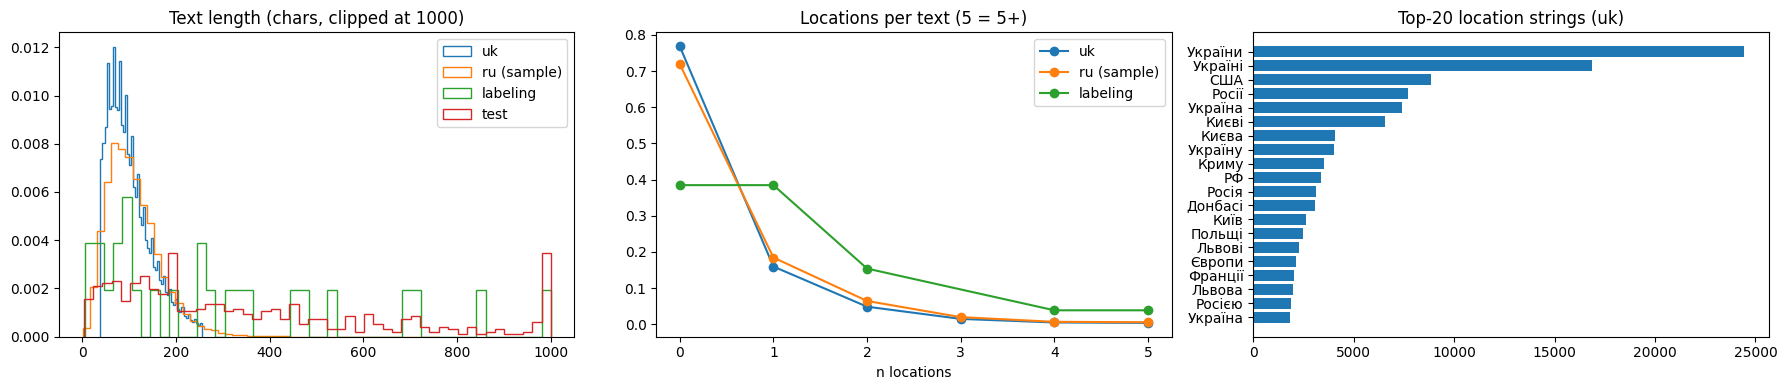

In [7]:
import ast
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

uk   = pd.read_csv("data/uk_geo_dataset.csv")
ru   = pd.read_csv("data/ru_geo_dataset.csv", nrows=300_000)  # 8M rows is too much for EDA
lab  = pd.read_csv("data/labeling_sample.csv")
test = pd.read_csv("data/test.csv")
sets = {"uk": uk, "ru (sample)": ru, "labeling": lab, "test": test}

for name, df in sets.items():
    df["text"] = df["text"].fillna("").astype(str)
    df["len"] = df["text"].str.len()
    if "loc_markers" in df:
        df["spans"] = df["loc_markers"].apply(ast.literal_eval)
        df["n_loc"] = df["spans"].str.len()

# --- summary numbers ---
for name, df in sets.items():
    newline_share = df["text"].str.contains("\n").mean()
    msg = f"{name:12s} n={len(df):>9,}  median len={df['len'].median():>4.0f}  max len={df['len'].max():>5}  has newline={newline_share:.1%}"
    if "n_loc" in df:
        msg += f"  0 locs={(df['n_loc'] == 0).mean():.1%}  mean locs={df['n_loc'].mean():.2f}"
    print(msg)

# --- most common location strings ---
def loc_strings(df):
    return [t[s:e] for t, spans in zip(df["text"], df["spans"]) for s, e in spans]

top = Counter(loc_strings(uk)).most_common(20)
print("\nlabeling_sample locations:", loc_strings(lab))

# --- does test look like train? (characters the model would never have seen) ---
train_chars = set("".join(uk["text"].sample(100_000, random_state=0)))
test_text = "".join(test["text"])
print(f"\nShare of test characters unseen in uk train: {sum(c not in train_chars for c in test_text) / len(test_text):.2%}")
for t in test["text"].sample(3, random_state=0):
    print("TEST:", repr(t[:150]))
for t in uk["text"].sample(3, random_state=0):
    print("UK:  ", repr(t[:150]))

# --- 3 plots ---
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, df in sets.items():
    ax[0].hist(df["len"].clip(upper=1000), bins=50, density=True, histtype="step", label=name)
ax[0].set(title="Text length (chars, clipped at 1000)"); ax[0].legend()

for name in ["uk", "ru (sample)", "labeling"]:
    vc = sets[name]["n_loc"].clip(upper=5).value_counts(normalize=True).sort_index()
    ax[1].plot(vc.index, vc.values, marker="o", label=name)
ax[1].set(title="Locations per text (5 = 5+)", xlabel="n locations"); ax[1].legend()

words, counts = zip(*top)
ax[2].barh(words[::-1], counts[::-1]); ax[2].set(title="Top-20 location strings (uk)")
plt.tight_layout(); plt.show()

In [8]:
import re
import string
from typing import List

def hard_processing(text):
    # NOTE: no f-prefix in the original -> this only strips . ( ) { } and some Latin letters,
    # NOT commas/apostrophes/hyphens. Kept as-is to match Kaggle's scorer.
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p = 0.0, 0.0, 0.0, 0.0
    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set(hard_processing(s) for s in y_true_sample)
        y_pred_sample = set(hard_processing(s) for s in y_pred_sample)
        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        precision = 1.0 if p == 0 else 0.0
    else:
        precision = tp / (tp + fp)
    if tp + fn == 0:
        recall = 1.0 if p == 0 else 0.0
    else:
        recall = tp / (tp + fn)

    f1 = 0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return round(f1, 8)

## 2. Validation


In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

uk = pd.read_csv("data/uk_geo_dataset.csv", usecols=["text", "loc_markers"])
ru = pd.read_csv("data/ru_geo_dataset.csv", usecols=["text", "loc_markers", "doc_id"], nrows=500_000)

uk["group"] = "uk_" + uk.index.astype(str)        # no group column -> each sentence is its own group
ru["group"] = "ru_" + ru["doc_id"].astype(str)    # all sentences of one article stay on the same side
pool = pd.concat([uk, ru.drop(columns="doc_id")], ignore_index=True)
pool["text"] = pool["text"].fillna("").astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(pool, groups=pool["group"]))

pool.to_parquet("data/pool.parquet")
np.savez("data/split.npz", train_idx=train_idx, val_idx=val_idx)

print(f"pool={len(pool):,}  train={len(train_idx):,}  val={len(val_idx):,}  val share={len(val_idx)/len(pool):.1%}")
assert not set(pool.loc[train_idx, "group"]) & set(pool.loc[val_idx, "group"]), "group leak!"

pool=1,510,000  train=1,207,471  val=302,529  val share=20.0%


## 3. Preprocessing


In [10]:
import re
from collections import Counter
import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence

# (1) Tokenizer: words (apostrophes/hyphens inside a word allowed) or single punctuation/emoji
TOKEN_RE = re.compile(r"\w+(?:['’ʼ-]\w+)*|[^\w\s]")

def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]

# (2) Char spans -> BIO tags per token, and back
TAGS = ["O", "B-LOC", "I-LOC"]
TAG2ID = {t: i for i, t in enumerate(TAGS)}

def spans_to_bio(tokens, spans):
    tags = ["O"] * len(tokens)
    for s, e in spans:
        inside = [i for i, (_, ts, te) in enumerate(tokens) if ts < e and te > s]  # tokens overlapping the span
        for k, i in enumerate(inside):
            tags[i] = "B-LOC" if k == 0 else "I-LOC"
    return tags

def bio_to_spans(tokens, tags):
    spans, cur = [], None
    for (_, ts, te), tag in zip(tokens, tags):
        if tag == "B-LOC" or (tag == "I-LOC" and cur is None):   # an I without B also starts a span
            if cur: spans.append(tuple(cur))
            cur = [ts, te]
        elif tag == "I-LOC":
            cur[1] = te                                           # extend the current span
        else:
            if cur: spans.append(tuple(cur))
            cur = None
    if cur: spans.append(tuple(cur))
    return spans

# (3) Vocabulary
PAD, UNK = 0, 1

def build_vocab(texts, min_freq=2):
    counts = Counter(tok for t in texts for tok, _, _ in tokenize(t))
    itos = ["<pad>", "<unk>"] + [w for w, c in counts.items() if c >= min_freq]
    return {w: i for i, w in enumerate(itos)}

# (4) Dataset + collate
class NERDataset(Dataset):
    def __init__(self, texts, spans_list, vocab):
        self.texts, self.spans_list, self.vocab = list(texts), list(spans_list), vocab

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        tokens = tokenize(self.texts[i])
        ids = [self.vocab.get(tok, UNK) for tok, _, _ in tokens]
        tags = [TAG2ID[t] for t in spans_to_bio(tokens, self.spans_list[i])]
        return torch.tensor(ids), torch.tensor(tags)

def collate_fn(batch):
    ids, tags = zip(*batch)
    ids = pad_sequence(ids, batch_first=True, padding_value=PAD)
    tags = pad_sequence(tags, batch_first=True, padding_value=-100)  # -100 = ignored by CrossEntropyLoss
    return ids, tags, ids != PAD                                     # mask: True for real tokens

In [11]:
import ast
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

pool = pd.read_parquet("data/pool.parquet")
pool["spans"] = pool["loc_markers"].apply(ast.literal_eval)
split = np.load("data/split.npz")
train_df = pool.iloc[split["train_idx"]]
val_df = pool.iloc[split["val_idx"]]
train_df = train_df[train_df["text"].str.strip() != ""]   # empty texts give 0 tokens -> drop
val_df = val_df[val_df["text"].str.strip() != ""]

vocab = build_vocab(train_df["text"], min_freq=2)          # train only -> no leak from val
print(f"vocab size: {len(vocab):,}")

# 3 examples: gold spans vs spans rebuilt from BIO tags
for text, spans in train_df[train_df["spans"].str.len() > 0][["text", "spans"]].head(3).values:
    tokens = tokenize(text)
    tags = spans_to_bio(tokens, spans)
    print("\nTEXT:   ", text)
    print("TAGGED: ", [(tok, tag) for (tok, _, _), tag in zip(tokens, tags) if tag != "O"])
    print("GOLD:   ", [text[s:e] for s, e in spans])
    print("REBUILT:", [text[s:e] for s, e in bio_to_spans(tokens, tags)])

# round-trip accuracy and unknown-word rate on samples
sample = train_df.sample(20_000, random_state=0)
ok = np.mean([bio_to_spans(tokenize(t), spans_to_bio(tokenize(t), sp)) == list(sp)
              for t, sp in zip(sample["text"], sample["spans"])])
val_tokens = [tok for t in val_df["text"].sample(20_000, random_state=0) for tok, _, _ in tokenize(t)]
print(f"\nspans recovered exactly: {ok:.2%}   val <unk> rate: {np.mean([tok not in vocab for tok in val_tokens]):.2%}")

ids, tags, mask = next(iter(DataLoader(NERDataset(train_df["text"][:4], train_df["spans"][:4], vocab),
                                       batch_size=4, collate_fn=collate_fn)))
print("batch shapes:", ids.shape, tags.shape, "| real tokens per row:", mask.sum(1).tolist())

vocab size: 375,239

TEXT:    Подібні розіграші проводили в Великій Британії.
TAGGED:  [('Великій', 'B-LOC'), ('Британії', 'I-LOC')]
GOLD:    ['Великій Британії']
REBUILT: ['Великій Британії']

TEXT:    У Львові 34-річний мешканець Яворівського району під час конфлікту жорстоко побив жінку, від спричинених травм вона померла на місці події.
TAGGED:  [('Львові', 'B-LOC'), ('Яворівського', 'B-LOC'), ('раи', 'I-LOC'), ('̆', 'I-LOC'), ('ону', 'I-LOC')]
GOLD:    ['Львові', 'Яворівського району']
REBUILT: ['Львові', 'Яворівського району']

TEXT:    Нагадаємо, президент України Володимир Зеленський скликав позачергове засідання Верховної Ради на 17 березня.
TAGGED:  [('України', 'B-LOC')]
GOLD:    ['України']
REBUILT: ['України']

spans recovered exactly: 99.56%   val <unk> rate: 2.65%
batch shapes: torch.Size([4, 28]) torch.Size([4, 28]) | real tokens per row: [28, 12, 10, 8]


## 4. Baseline model + training


In [12]:
!pip install -q lightning wandb
import torch
import torch.nn as nn
import lightning as L
from lightning.pytorch.utilities import grad_norm
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

config = dict(
    rnn="lstm",          # "lstm" or "gru"
    emb_dim=128,
    hidden=256,
    num_layers=2,
    bidirectional=True,
    dropout=0.3,
    lr=1e-3,
    batch_size=256,
    max_epochs=10,
    patience=2,          # early stopping: epochs without val_f1 improvement
    grad_clip=1.0,
    val_size=20_000,     # val rows scored every epoch (the full 300k is too slow)
    seed=42,
)

class Tagger(L.LightningModule):
    def __init__(self, config, vocab_size, val_texts=None, val_spans=None):
        super().__init__()
        self.save_hyperparameters(ignore=["val_texts", "val_spans"])   # config + vocab_size -> W&B and checkpoint
        rnn_cls = nn.LSTM if config["rnn"] == "lstm" else nn.GRU
        self.emb = nn.Embedding(vocab_size, config["emb_dim"], padding_idx=PAD)
        self.rnn = rnn_cls(config["emb_dim"], config["hidden"], num_layers=config["num_layers"],
                           bidirectional=config["bidirectional"], batch_first=True,
                           dropout=config["dropout"] if config["num_layers"] > 1 else 0.0)
        out_dim = config["hidden"] * (2 if config["bidirectional"] else 1)
        self.drop = nn.Dropout(config["dropout"])
        self.head = nn.Linear(out_dim, len(TAGS))
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)        # -100 = padded positions
        self.val_texts, self.val_spans, self.val_preds = val_texts, val_spans, []

    def forward(self, ids, mask):
        x = self.emb(ids)
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        return self.head(self.drop(out))                              # (batch, seq_len, 3)

    def _loss(self, logits, tags):
        return self.loss_fn(logits.reshape(-1, len(TAGS)), tags.reshape(-1))

    def training_step(self, batch, batch_idx):
        ids, tags, mask = batch
        loss = self._loss(self(ids, mask), tags)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        ids, tags, mask = batch
        logits = self(ids, mask)
        self.log("val_loss", self._loss(logits, tags), on_epoch=True, prog_bar=True)
        for row, m in zip(logits.argmax(-1), mask):
            self.val_preds.append(row[m].tolist())                    # predicted tag ids, padding removed

    def on_validation_epoch_end(self):
        if len(self.val_preds) == len(self.val_texts):                # skip Lightning's 2-batch sanity check
            y_true, y_pred = [], []
            for text, spans, tag_ids in zip(self.val_texts, self.val_spans, self.val_preds):
                pred_spans = bio_to_spans(tokenize(text), [TAGS[t] for t in tag_ids])
                y_true.append([text[s:e] for s, e in spans])
                y_pred.append([text[s:e] for s, e in pred_spans])
            self.log("val_f1", comp_metric(y_true, y_pred), prog_bar=True)
        self.val_preds.clear()

    def on_before_optimizer_step(self, optimizer):
        self.log_dict(grad_norm(self, norm_type=2))                   # per-layer + total grad norm, before clipping

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.config["lr"])

In [13]:
import wandb
from torch.utils.data import DataLoader
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

L.seed_everything(config["seed"])
val_small = val_df.sample(config["val_size"], random_state=config["seed"])

train_dl = DataLoader(NERDataset(train_df["text"], train_df["spans"], vocab), batch_size=config["batch_size"],
                      shuffle=True, collate_fn=collate_fn, num_workers=2)
val_dl = DataLoader(NERDataset(val_small["text"], val_small["spans"], vocab), batch_size=config["batch_size"],
                    shuffle=False, collate_fn=collate_fn, num_workers=2)   # no shuffle: preds must match val_texts order

model = Tagger(config, len(vocab), val_small["text"].tolist(), val_small["spans"].tolist())

ckpt = ModelCheckpoint(monitor="val_f1", mode="max", save_top_k=1, filename="best-{epoch}-{val_f1:.4f}")
early = EarlyStopping(monitor="val_f1", mode="max", patience=config["patience"])
trainer = L.Trainer(
    max_epochs=config["max_epochs"],
    logger=WandbLogger(project="ua-locations-ner"),
    callbacks=[ckpt, early],
    gradient_clip_val=config["grad_clip"],
    log_every_n_steps=50,
    accelerator="auto",
)
trainer.fit(model, train_dl, val_dl)
print("best:", ckpt.best_model_path, ckpt.best_model_score)
wandb.finish()   # close the run so the next experiment starts a new one

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: You are using a CUDA device ('NVIDIA L4') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | '

wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: lyaroshenko (lyaroshenko-kse) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (2 outputs left out)

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

best: ./ua-locations-ner/kcaotmoa/checkpoints/best-epoch=3-val_f1=0.9099.ckpt tensor(0.9099, device='cuda:0')


epoch,▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▄▄▄▄▄▄▅▅▅▅▅▅▅▇▇▇▇▇▇▇████
grad_2.0_norm/emb.weight,▅▄▄█▃▂▃▃▃▂▂▂▂▂▂▃▄▅▂▂▄▁▃▂▄▃▂▂▂▁▃▃▃▂▅▂▃▁▃▁
grad_2.0_norm/head.bias,█▃▄▂▃▃▁▃▁▁▂▂▃▂▂▂▁▁▂▁▂▂▂▂▂▁▁▃▂▂▁▂▂▁▂▁▂▁▂▁
grad_2.0_norm/head.weight,█▄▅▄▇▃▂▃▂▅▂▃▂▂▂▃▃▃▁▃▁▂▂▂▃▅▂▂▃▁▂▁▁▂▂▁▁▂▁▁
grad_2.0_norm/rnn.bias_hh_l0,▇█▅▄▅▃▃▇▂▃▃▃▂▄▂▃▃▃▂▂▂▂▁▂▂▂▁▄▂▃▂▂▂▁▂▂▁▁▂▂
grad_2.0_norm/rnn.bias_hh_l0_reverse,▄██▄▄▄▄▃▂▃▃▃▆▃▂▂▃▂▃▄▃▂▂▂▂▂▃▃▂▂▄▂▅▂▂▁▂▃▁▂
grad_2.0_norm/rnn.bias_hh_l1,▅▄▄▃▅█▅▇▄▂▄▃▅▄▃▂▄▂▇▃▂▂▂▂▆▂▂▂▂▂▁▁▁▁▁▁▁▃▁▁
grad_2.0_norm/rnn.bias_hh_l1_reverse,▂▃█▇▇▅▄▇▆▂▂▃▂▂▃▃▂▂▇▃▂▂▃▂▂▁▂█▂▂▁▂▃▂▇▁▄▁▁▁
grad_2.0_norm/rnn.bias_ih_l0,▆▇█▄▆▅▄██▂▃▃▇▁▂▅▂▃▇▄▃▃▄▄▃▂▃▃▃▃▃▂▁▂▁▂▃▁▂▃
grad_2.0_norm/rnn.bias_ih_l0_reverse,▇█▃▃▂▃▁▂▂▂▂▂▂▃▂▃▁▁▂▁▂▃▁▂▂▁▂▂▁▁▂▂▂▁▂▁▁▁▃▁
+16,...


## 5. Predictions -> submission


In [16]:
import pickle
assert len(vocab) == model.hparams.vocab_size, "this vocab doesn't match the trained model"
pickle.dump(vocab, open("vocab.pkl", "wb"))

In [14]:
import json
import numpy as np
import pandas as pd

STRIP_CHARS = " ,;:!?\"'«»()—–-"   # the metric keeps commas/quotes (missing f-string), so trim them from span edges

def tags_to_spans(tokens, tags, mode="strict"):
    spans, cur = [], None
    for (_, ts, te), tag in zip(tokens, tags):
        if tag == "O":
            cur = None                                            # O closes the current entity
        elif cur is not None and (tag == "I-LOC" or mode == "loose"):
            cur[1] = te                                           # continue: I (strict) or any non-O (loose)
        elif tag == "B-LOC" or mode == "loose":
            cur = [ts, te]                                        # start a new entity
            spans.append(cur)
        # strict mode: I-LOC with no open entity is ignored
    return [tuple(s) for s in spans]

@torch.no_grad()
def predict_probs(model, texts, vocab, batch_size=256):
    model.eval()
    # 1) tokenize each full text, then cut its token list into lines (chunks)
    all_tokens, chunks = [], []                                   # chunk = (text index, first token, last token + 1)
    for i, text in enumerate(texts):
        tokens = tokenize(text)
        all_tokens.append(tokens)
        start = 0
        for j in range(1, len(tokens) + 1):
            if j == len(tokens) or "\n" in text[tokens[j - 1][2]:tokens[j][1]]:
                chunks.append((i, start, j))
                start = j
    # 2) run the model on chunks in batches and put the probabilities back per text
    probs = [np.zeros((len(t), len(TAGS)), dtype=np.float32) for t in all_tokens]
    for b in range(0, len(chunks), batch_size):
        batch = chunks[b:b + batch_size]
        ids = [torch.tensor([vocab.get(tok, UNK) for tok, _, _ in all_tokens[i][s:e]]) for i, s, e in batch]
        ids = pad_sequence(ids, batch_first=True, padding_value=PAD).to(model.device)
        p = model(ids, ids != PAD).softmax(-1).cpu().numpy()
        for row, (i, s, e) in zip(p, batch):
            probs[i][s:e] = row[:e - s]
    return all_tokens, probs                                      # probs[i]: (n_tokens_i, 3) for O, B-LOC, I-LOC

def probs_to_locations(texts, tokens_list, probs_list, mode="strict"):
    all_locs = []
    for text, tokens, probs in zip(texts, tokens_list, probs_list):
        tags = [TAGS[k] for k in probs.argmax(-1)]
        locs = [text[s:e].strip(STRIP_CHARS) for s, e in tags_to_spans(tokens, tags, mode)]
        all_locs.append(list(dict.fromkeys(l for l in locs if l)))   # drop empty, remove duplicates, keep order
    return all_locs

def make_submission(test_df, tokens_list, probs_list, mode="strict", path="submission.csv"):
    locs = probs_to_locations(test_df["text"], tokens_list, probs_list, mode)
    sub = pd.DataFrame({"text_id": test_df["text_id"],
                        "locations": [json.dumps(l, ensure_ascii=False) for l in locs]})
    sub.to_csv(path, index=False)
    return sub

In [17]:
import ast, pickle

model = Tagger.load_from_checkpoint(ckpt.best_model_path).to("cuda" if torch.cuda.is_available() else "cpu")
vocab = pickle.load(open("vocab.pkl", "rb"))

lab = pd.read_csv("data/labeling_sample.csv")
test = pd.read_csv("data/test.csv")
for df in (lab, test):
    df["text"] = df["text"].fillna("").astype(str)

lab_tokens, lab_probs = predict_probs(model, lab["text"], vocab)
gold = lab["locations"].apply(ast.literal_eval).tolist()
for mode in ["strict", "loose"]:
    print(f"{mode:6s} labeling_sample F1 = {comp_metric(gold, probs_to_locations(lab['text'], lab_tokens, lab_probs, mode)):.4f}")

test_tokens, test_probs = predict_probs(model, test["text"], vocab)
sub = make_submission(test, test_tokens, test_probs, mode="strict")      # use the better mode from above
pickle.dump((test_tokens, test_probs), open("test_probs.pkl", "wb"))     # for threshold tuning / ensembling later
print(sub.head(10))

strict labeling_sample F1 = 0.5479
loose  labeling_sample F1 = 0.5479
   text_id  \
0        0   
1        1   
2        2   
3        3   
4        4   
5        5   
6        6   
7        7   
8        8   
9        9   

                                                                    locations  
0                                                                    ["Київ"]  
1                                       ["Києві", "Шулявського шляхопроводу"]  
2                ["Гоголеве", "Миргородського району", "Полтавської області"]  
3                                                                          []  
4                                         ["проспекті Академіка Глушкова, 9"]  
5                                                                ["Броварах"]  
6                                                                          []  
7                                                         ["Забуччя", "Київ"]  
8                                                      

In [18]:
sub = pd.read_csv("submission.csv")
print(sub.shape, sub.columns.tolist())               # expect (477, 2) ['text_id', 'locations']
print((sub["locations"] != "[]").mean())             # share of texts with at least one location
print(sub[sub["locations"] != "[]"].head(10))

(477, 2) ['text_id', 'locations']
0.710691823899371
    text_id  \
0         0   
1         1   
2         2   
4         4   
5         5   
7         7   
8         8   
9         9   
11       11   
12       12   

                                                                     locations  
0                                                                     ["Київ"]  
1                                        ["Києві", "Шулявського шляхопроводу"]  
2                 ["Гоголеве", "Миргородського району", "Полтавської області"]  
4                                          ["проспекті Академіка Глушкова, 9"]  
5                                                                 ["Броварах"]  
7                                                          ["Забуччя", "Київ"]  
8                                                                  ["Дарниця"]  
9   ["Солом’янському районі столиці", "вулиці Новій", "Солом’янському районі"]  
11                                                ["К

In [19]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Experiments


In [21]:
# ===================== EXPERIMENTS: setup =====================
import os, gzip, ast
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import lightning as L
import wandb
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from lightning.pytorch.utilities import grad_norm
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint, LearningRateMonitor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_WORKERS = os.cpu_count()

lab = pd.read_csv("data/labeling_sample.csv")
test = pd.read_csv("data/test.csv")
for df in (lab, test):
    df["text"] = df["text"].fillna("").astype(str)
lab_gold = lab["locations"].apply(ast.literal_eval).tolist()

base_config = dict(name="baseline", rnn="lstm", emb_dim=128, hidden=256, num_layers=2, bidirectional=True,
                   dropout=0.3, lr=1e-3, batch_size=256, max_epochs=10, patience=2, grad_clip=1.0,
                   val_size=20_000, seed=42, optimizer="adam")

In [22]:
# ===================== EXPERIMENTS: model (replaces the earlier Tagger) =====================
class Tagger(L.LightningModule):
    def __init__(self, config, vocab_size, val_texts=None, val_spans=None, pretrained=None):
        super().__init__()
        self.save_hyperparameters(ignore=["val_texts", "val_spans", "pretrained"])
        rnn_cls = nn.LSTM if config["rnn"] == "lstm" else nn.GRU
        self.emb = nn.Embedding(vocab_size, config["emb_dim"], padding_idx=PAD)
        if pretrained is not None:
            self.emb.weight.data.copy_(pretrained)                        # (e) fastText init
        self.rnn = rnn_cls(config["emb_dim"], config["hidden"], num_layers=config["num_layers"],
                           bidirectional=config["bidirectional"], batch_first=True,
                           dropout=config["dropout"] if config["num_layers"] > 1 else 0.0)
        out_dim = config["hidden"] * (2 if config["bidirectional"] else 1)
        self.drop = nn.Dropout(config["dropout"])
        self.head = nn.Linear(out_dim, len(TAGS))
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
        self.val_texts, self.val_spans, self.val_preds = val_texts, val_spans, []

    def forward(self, ids, mask):
        x = self.emb(ids)
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        return self.head(self.drop(out))

    def _loss(self, logits, tags):
        return self.loss_fn(logits.reshape(-1, len(TAGS)), tags.reshape(-1))

    def training_step(self, batch, batch_idx):
        ids, tags, mask = batch
        loss = self._loss(self(ids, mask), tags)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        ids, tags, mask = batch
        logits = self(ids, mask)
        self.log("val_loss", self._loss(logits, tags), on_epoch=True, prog_bar=True)
        for row, m in zip(logits.argmax(-1), mask):
            self.val_preds.append(row[m].tolist())

    def on_validation_epoch_end(self):
        if self.val_texts is not None and len(self.val_preds) == len(self.val_texts):
            y_true, y_pred = [], []
            for text, spans, tag_ids in zip(self.val_texts, self.val_spans, self.val_preds):
                pred_spans = bio_to_spans(tokenize(text), [TAGS[t] for t in tag_ids])
                y_true.append([text[s:e] for s, e in spans])
                y_pred.append([text[s:e] for s, e in pred_spans])
            self.log("val_f1", comp_metric(y_true, y_pred), prog_bar=True)
        self.val_preds.clear()

    def on_before_optimizer_step(self, optimizer):
        self.log_dict(grad_norm(self, norm_type=2))

    def configure_optimizers(self):
        cfg = self.hparams.config
        if cfg.get("optimizer", "adam") == "adam":
            return torch.optim.Adam(self.parameters(), lr=cfg["lr"])
        opt = torch.optim.AdamW(self.parameters(), lr=cfg["lr"], weight_decay=cfg.get("weight_decay", 0.01))   # (d)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"],
                                                    total_steps=self.trainer.estimated_stepping_batches)
        return {"optimizer": opt, "lr_scheduler": {"scheduler": sched, "interval": "step"}}

In [23]:
# ===================== EXPERIMENTS: one function = one full run =====================
def run_experiment(config, vocab, pretrained=None, notes=""):
    L.seed_everything(config["seed"])
    val_small = val_df.sample(config["val_size"], random_state=config["seed"])
    train_dl = DataLoader(NERDataset(train_df["text"], train_df["spans"], vocab), batch_size=config["batch_size"],
                          shuffle=True, collate_fn=collate_fn, num_workers=NUM_WORKERS)
    val_dl = DataLoader(NERDataset(val_small["text"], val_small["spans"], vocab), batch_size=config["batch_size"],
                        shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)

    # 1) train
    model = Tagger(config, len(vocab), val_small["text"].tolist(), val_small["spans"].tolist(), pretrained=pretrained)
    ckpt = ModelCheckpoint(dirpath=f"checkpoints/{config['name']}", filename="best-{epoch}-{val_f1:.4f}",
                           monitor="val_f1", mode="max", save_top_k=1)
    trainer = L.Trainer(max_epochs=config["max_epochs"],
                        logger=WandbLogger(project="ua-locations-ner", name=config["name"]),
                        callbacks=[ckpt, EarlyStopping(monitor="val_f1", mode="max", patience=config["patience"]),
                                   LearningRateMonitor(logging_interval="step")],
                        gradient_clip_val=config["grad_clip"], log_every_n_steps=50, accelerator="auto")
    trainer.fit(model, train_dl, val_dl)

    # 2) best checkpoint -> labeling_sample F1 (both merge modes) -> submission file
    best = Tagger.load_from_checkpoint(ckpt.best_model_path).to(DEVICE)
    lab_tokens, lab_probs = predict_probs(best, lab["text"], vocab)
    lab_f1 = {m: comp_metric(lab_gold, probs_to_locations(lab["text"], lab_tokens, lab_probs, m))
              for m in ("strict", "loose")}
    mode = max(lab_f1, key=lab_f1.get)
    test_tokens, test_probs = predict_probs(best, test["text"], vocab)
    make_submission(test, test_tokens, test_probs, mode=mode, path=f"submission_{config['name']}.csv")

    cv = round(ckpt.best_model_score.item(), 4)
    wandb.run.summary.update({"best_val_f1": cv, "lab_f1_strict": lab_f1["strict"], "lab_f1_loose": lab_f1["loose"]})
    wandb.finish()
    del model, best
    torch.cuda.empty_cache()

    return {"experiment": config["name"], "CV score": cv, "LB score": "",
            "notes": f"{notes}; lab F1 strict={lab_f1['strict']:.3f} loose={lab_f1['loose']:.3f}; "
                     f"submitted mode={mode}; ckpt={os.path.basename(ckpt.best_model_path)}".lstrip("; ")}

results = []

In [24]:
# ===================== EXPERIMENTS: baseline + (a)-(d), word tokens =====================
experiments = [
    ({**base_config}, "BiLSTM, 2 layers, Adam (re-run in the same pipeline)"),
    ({**base_config, "name": "gru", "rnn": "gru"}, "(a) GRU instead of LSTM"),
    ({**base_config, "name": "1-layer", "num_layers": 1}, "(b) 1 layer; between-layer dropout off"),
    ({**base_config, "name": "unidirectional", "bidirectional": False}, "(c) forward direction only"),
    ({**base_config, "name": "adamw-onecycle", "optimizer": "adamw_onecycle", "lr": 3e-3, "patience": 100},
     "(d) AdamW wd=0.01 + OneCycleLR, peak lr 3e-3; early stopping off so the cycle completes"),
]
for cfg, notes in experiments:
    results.append(run_experiment(cfg, vocab, notes=notes))
    pd.DataFrame(results).to_csv("results.csv", index=False)       # saved after every run

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ emb     │ Embedding        │ 48.0 M │ train │     0 │
│ 1 │ rnn     │ LSTM             │  2.4 M │ train │     0 │
│ 2 │ drop    │ Dropout          │      0 │ train │     0 │
│ 3 │ head    │ Linear           │  1.5 K │ train │     0 │
│ 4 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 50.4 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 50.4 M                                                                                               
Total estimated model params size (MB): 201.598                                                                    
Modules in train mode: 5                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

... (25 outputs left out)

Trainable params: 50.4 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 50.4 M                                                                                               
Total estimated model params size (MB): 201.598                                                                    
Modules in train mode: 5                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▃▃▃▄▄▅▅▅▆▆▆▆▆▆▆▆▇███
grad_2.0_norm/emb.weight,▂▆▅▅▄▄▃▃▄▅▃▄█▄▄▃▄▄▂▄▄▂▂▃▃▅▄▄▃▅▃▃▂▃▂▂▁▁▁▁
grad_2.0_norm/head.bias,▃▅█▂▃▂▂▂▂▂▃▂▂▁▂▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/head.weight,█▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_hh_l0,▂█▆▃▅▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_hh_l0_reverse,▃▅▅█▇▄▃▃▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▁▁▃▂▂▂▁▂▂▂▂▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_hh_l1,▂█▇▄▄▂▂▂▁▂▁▂▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_hh_l1_reverse,▁▂█▂▅▄▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_ih_l0,▂▅▃▅▇▆█▃▄▄▂▂▂▁▁▁▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad_2.0_norm/rnn.bias_ih_l0_reverse,▆█▆▂▄▂▂▂▂▂▂▂▂▁▁▂▂▂▁▂▁▂▁▁▂▁▁▁▂▁▂▁▁▂▁▁▁▁▁▁
+17,...


In [25]:
# ===================== EXPERIMENTS: (e) fastText cc.uk.300 =====================
!wget -q -nc https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.uk.300.vec.gz

def load_fasttext(path, vocab, dim=300):
    needed = set(vocab) | {w.lower() for w in vocab}
    vecs = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        next(f)                                                    # header line: "n_words dim"
        for line in f:
            word, rest = line.rstrip().split(" ", 1)
            if word in needed:
                vecs[word] = np.asarray(rest.split(" "), dtype=np.float32)
    weights = np.random.normal(0, 0.1, (len(vocab), dim)).astype(np.float32)
    weights[PAD] = 0
    hits = 0
    for w, i in vocab.items():
        v = vecs.get(w, vecs.get(w.lower()))                       # exact form first, then lowercase
        if v is not None:
            weights[i] = v
            hits += 1
    return torch.tensor(weights), hits / len(vocab)

pretrained, hit_rate = load_fasttext("cc.uk.300.vec.gz", vocab)
print(f"fastText vectors found for {hit_rate:.1%} of vocab")
results.append(run_experiment({**base_config, "name": "fasttext", "emb_dim": 300}, vocab, pretrained=pretrained,
                              notes=f"(e) cc.uk.300 init, fine-tuned; emb_dim 300; vocab hit rate {hit_rate:.1%}"))
pd.DataFrame(results).to_csv("results.csv", index=False)
del pretrained

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


fastText vectors found for 77.1% of vocab


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ emb     │ Embedding        │  112 M │ train │     0 │
│ 1 │ rnn     │ LSTM             │  2.7 M │ train │     0 │
│ 2 │ drop    │ Dropout          │      0 │ train │     0 │
│ 3 │ head    │ Linear           │  1.5 K │ train │     0 │
│ 4 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 115 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 115 M                                                                                                
Total estimated model params size (MB): 461.172                                                                    
Modules in train mode: 5                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▃▃▃▃▃▃▃▃▆▆▆▆▆▆██████████
grad_2.0_norm/emb.weight,██▇▅▅▄▃▄▃▅▃▅▃▄▄▃▄▅▆▇▄▃▃▃▃▂▃▃▂▃▃▂▂▃▂▂▄▄▁▂
grad_2.0_norm/head.bias,▅█▇▅▄▄▆▃▄▄▂▂▂▂▃▅▃▂▂▂▂▃▁▂▃▂▂▁▂▄▂▂▂▂▁▂▂▂▂▁
grad_2.0_norm/head.weight,▄▆▅▆▅█▃▄▃▃▂▂▂▂▂▅▃▂▁▃▃▁▁▂▂▂▁▁▂▁▁▁▂▁▁▃▁▁▂▁
grad_2.0_norm/rnn.bias_hh_l0,█▂▁▂▁▂▁▂▁▁▂▁▂▂▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▁▂▂▁▁
grad_2.0_norm/rnn.bias_hh_l0_reverse,▄█▃▂▃▂▃▂▂▂▂▂▂▂▄▂▁▂▃▄▁▁▁▂▂▁▅▄▃▂▂▁▂▁▁▂▂▁▁▁
grad_2.0_norm/rnn.bias_hh_l1,▃█▅▄▃▃▄▃▃▃▂▂▂▂▂▂▂▂▁▂▁▁▁▂▂▁▂▁▂▂▁▁▂▂▂▂▁▁▂▁
grad_2.0_norm/rnn.bias_hh_l1_reverse,▄▅▆▃▅▃▃▂▅█▂▃▄▄▃▃▂▄▃▃▂▃▃▂▂▄▁▂▄▂▁▃▅▁▂▁▃▃▂▁
grad_2.0_norm/rnn.bias_ih_l0,▇▇▄▆█▅▅▃▄▃▅▃▃▄▂▃▃▄▃▃▄▂▃▂▂▄▂▂▂▁▃▂▄▂▂▂▄▂▂▁
grad_2.0_norm/rnn.bias_ih_l0_reverse,▅█▆▆▅▄▇▅▅▄▄▃▅▃▆▃▃▇▅▃▄▂▄▄▂▃▃▁▃▃▃▂▃▂▃▄▂▁▃▂
+17,...


In [26]:
# ===================== EXPERIMENTS: (f) BPE subword tokens =====================
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

bpe = Tokenizer(models.BPE(unk_token="<unk>"))
bpe.pre_tokenizer = pre_tokenizers.Whitespace()
bpe.train_from_iterator(train_df["text"], trainers.BpeTrainer(vocab_size=30_000, special_tokens=["<pad>", "<unk>"]),
                        length=len(train_df))
bpe.save("bpe.json")
bpe_vocab = bpe.get_vocab()                                        # "<pad>" -> 0, "<unk>" -> 1

word_tokenize = tokenize                                           # keep the word tokenizer to restore later
def tokenize(text):
    enc = bpe.encode(text)
    return [(t, s, e) for t, (s, e) in zip(enc.tokens, enc.offsets)]

try:
    results.append(run_experiment({**base_config, "name": "bpe-30k"}, bpe_vocab,
                                  notes="(f) BPE 30k subwords; labels: first overlapping subword B, rest I"))
    pd.DataFrame(results).to_csv("results.csv", index=False)
finally:
    tokenize = word_tokenize                                       # back to word tokens for any later cell

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ emb     │ Embedding        │  3.8 M │ train │     0 │
│ 1 │ rnn     │ LSTM             │  2.4 M │ train │     0 │
│ 2 │ drop    │ Dropout          │      0 │ train │     0 │
│ 3 │ head    │ Linear           │  1.5 K │ train │     0 │
│ 4 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 6.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 6.2 M                                                                                                
Total estimated model params size (MB): 24.836                                                                     
Modules in train mode: 5                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

epoch,▁▁▁▁▁▁▂▂▂▂▂▄▄▄▄▄▄▄▄▄▄▄▄▅▅▅▅▅▇▇▇▇▇▇▇█████
grad_2.0_norm/emb.weight,▅▄▄▆▆▃▃▂▅▅▄▅▁▂▅▅▄▂▄▆▁▄▃▂▃▂█▅▅▂▁█▄▆▂▇▄▆▆▅
grad_2.0_norm/head.bias,█▂▁▂▃▂▂▄▁▃▁▁▂▁▂▁▃▁▂▂▂▂▂▂▁▁▃▁▂▂▁▁▂▃▂▂▂▃▁▁
grad_2.0_norm/head.weight,██▄▆▅▂▂▂▄▂▂▂▃▄▃▂▂▂▁▃▂▂▁▂▂▁▂▂▁▂▂▁▁▂▂▂▁▁▂▂
grad_2.0_norm/rnn.bias_hh_l0,█▆▅▆▄▆▂█▄▃▃▂▂▅▂▂▂▂▂▁▂▁▁▂▂▂▂▂▂▂▂▂▁▂▂▃▃▂▄▁
grad_2.0_norm/rnn.bias_hh_l0_reverse,█▅▅▆▄▂▅▅▄▃▂▂▂▂▂▂▃▃▃▃▂▃▄▅▂▂▃▁▂▂▄▂▂▂▃▂▁▃▇▁
grad_2.0_norm/rnn.bias_hh_l1,▄▄▅▄▄▄▂█▄▃▄▂▃▃▃▃▂▂▂▃▂▂▂▁▃▂▄▂▂▂▂▃▂▂▂▂▁▂▂▁
grad_2.0_norm/rnn.bias_hh_l1_reverse,▄▄▄▇▇█▇▅▇▄▅▂▄▃▁▃▄▂▅▂▂▂▂▅▆▅▂▃▃▂▂▂▂▁▃▅▁▃▃█
grad_2.0_norm/rnn.bias_ih_l0,▆▄█▃▇▂▂▂▁▂▃▁▂▂▂▁▂▁▂▁▂▂▂▂▂▁▁▁▂▂▁▂▁▁▃▁▁▁▁▁
grad_2.0_norm/rnn.bias_ih_l0_reverse,▄▅▇█▂▂▂▃▂▄▂▃▁▂▂▁▂▂▁▃▁▁▁▂▁▁▁▁▁▁▂▁▁▁▂▂▂▂▂▂
+17,...


In [27]:
# ===================== EXPERIMENTS: results table =====================
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)
print(results_df.to_markdown(index=False))                         # paste into the report; fill LB after submitting
results_df

| experiment     |   CV score | LB score   | notes                                                                                                                                                                                 |
|:---------------|-----------:|:-----------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| baseline       |     0.9099 |            | BiLSTM, 2 layers, Adam (re-run in the same pipeline); lab F1 strict=0.548 loose=0.548; submitted mode=strict; ckpt=best-epoch=3-val_f1=0.9099.ckpt                                    |
| gru            |     0.9047 |            | (a) GRU instead of LSTM; lab F1 strict=0.615 loose=0.593; submitted mode=strict; ckpt=best-epoch=2-val_f1=0.9047.ckpt                                                                 |
| 1-layer        |     0.9001 |            | (b) 1 layer; between-layer dropout off;

,experiment,CV score,LB score,notes
0,baseline,0.9099,,"BiLSTM, 2 layers, Adam (re-run in the same pipeline); lab F1 strict=0.548 loose=0.548; submitted mode=strict; ckpt=best-epoch=3-val_f1=0.9099.ckpt"
1,gru,0.9047,,(a) GRU instead of LSTM; lab F1 strict=0.615 loose=0.593; submitted mode=strict; ckpt=best-epoch=2-val_f1=0.9047.ckpt
2,1-layer,0.9001,,(b) 1 layer; between-layer dropout off; lab F1 strict=0.657 loose=0.622; submitted mode=strict; ckpt=best-epoch=2-val_f1=0.9001.ckpt
3,unidirectional,0.8898,,(c) forward direction only; lab F1 strict=0.583 loose=0.575; submitted mode=strict; ckpt=best-epoch=3-val_f1=0.8898.ckpt
4,adamw-onecycle,0.9100,,"(d) AdamW wd=0.01 + OneCycleLR, peak lr 3e-3; early stopping off so the cycle completes; lab F1 strict=0.613 loose=0.605; submitted mode=strict; ckpt=best-epoch=4-val_f1=0.9100.ckpt"
5,fasttext,0.9152,,"(e) cc.uk.300 init, fine-tuned; emb_dim 300; vocab hit rate 77.1%; lab F1 strict=0.615 loose=0.615; submitted mode=strict; ckpt=best-epoch=1-val_f1=0.9152.ckpt"
6,bpe-30k,0.9072,,"(f) BPE 30k subwords; labels: first overlapping subword B, rest I; lab F1 strict=0.582 loose=0.568; submitted mode=strict; ckpt=best-epoch=3-val_f1=0.9072.ckpt"


## 7. ensemble


## 8. adversial validation
